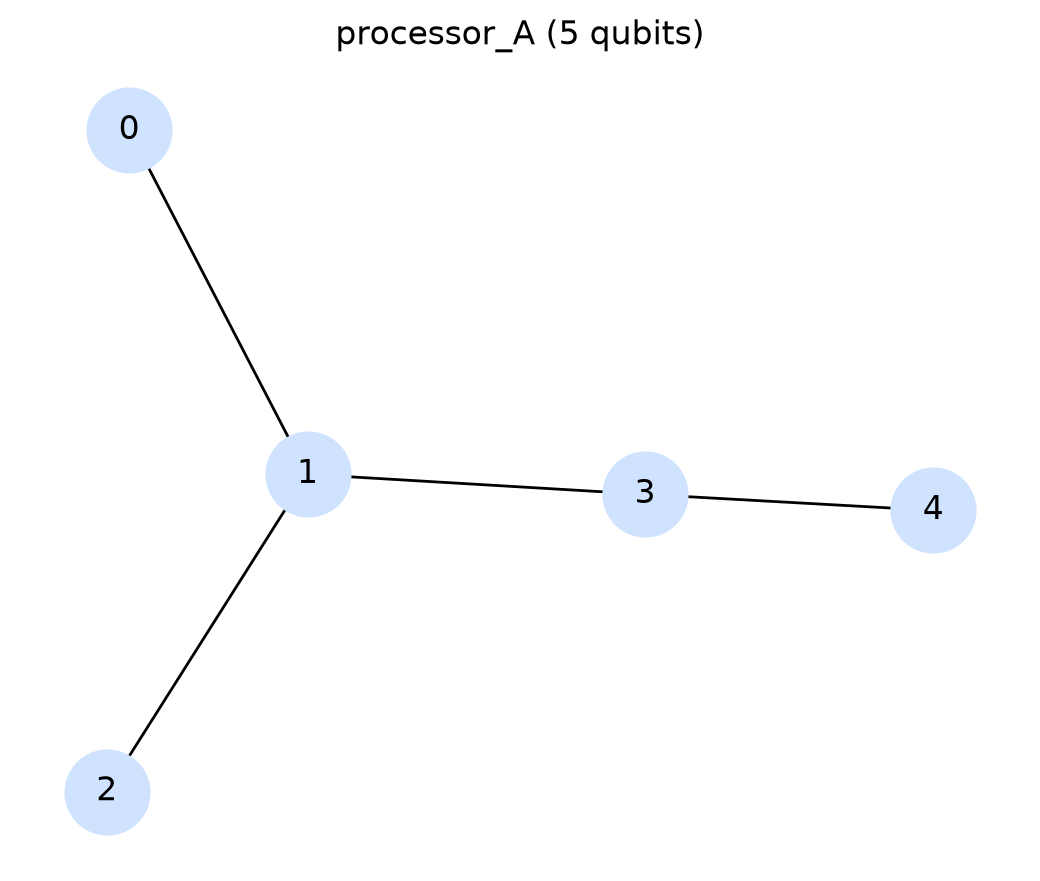

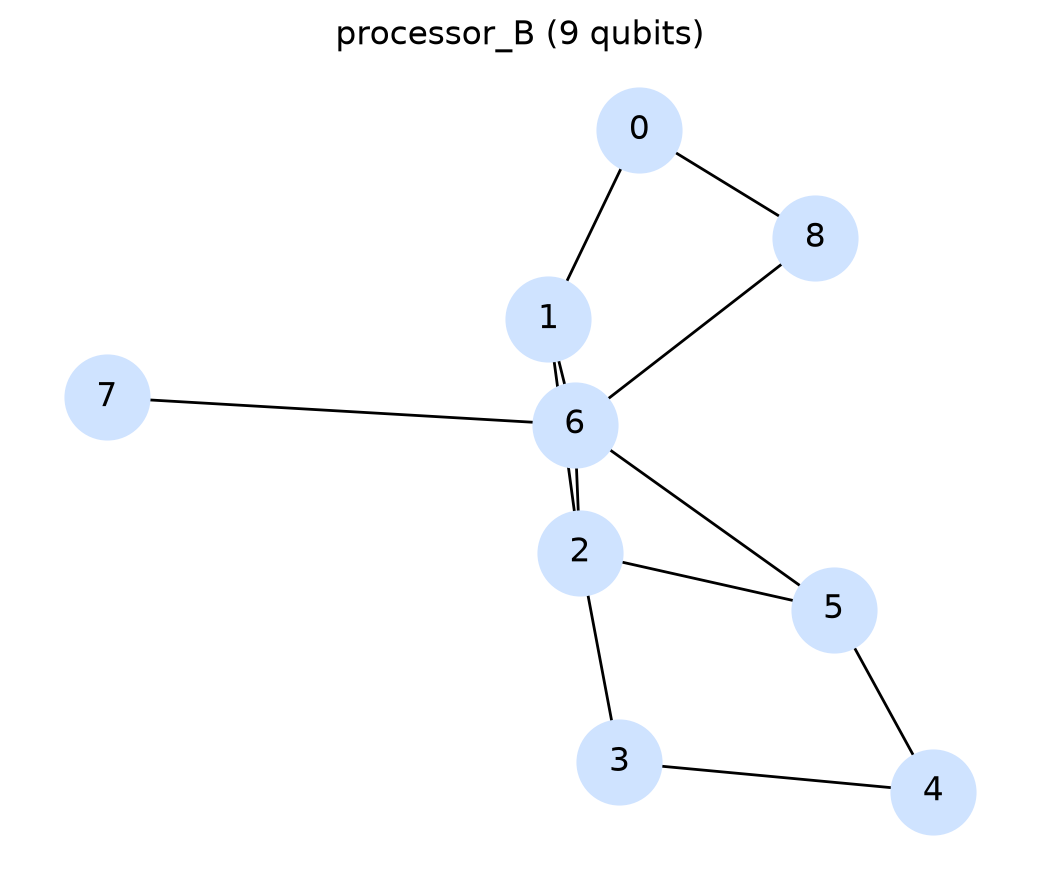

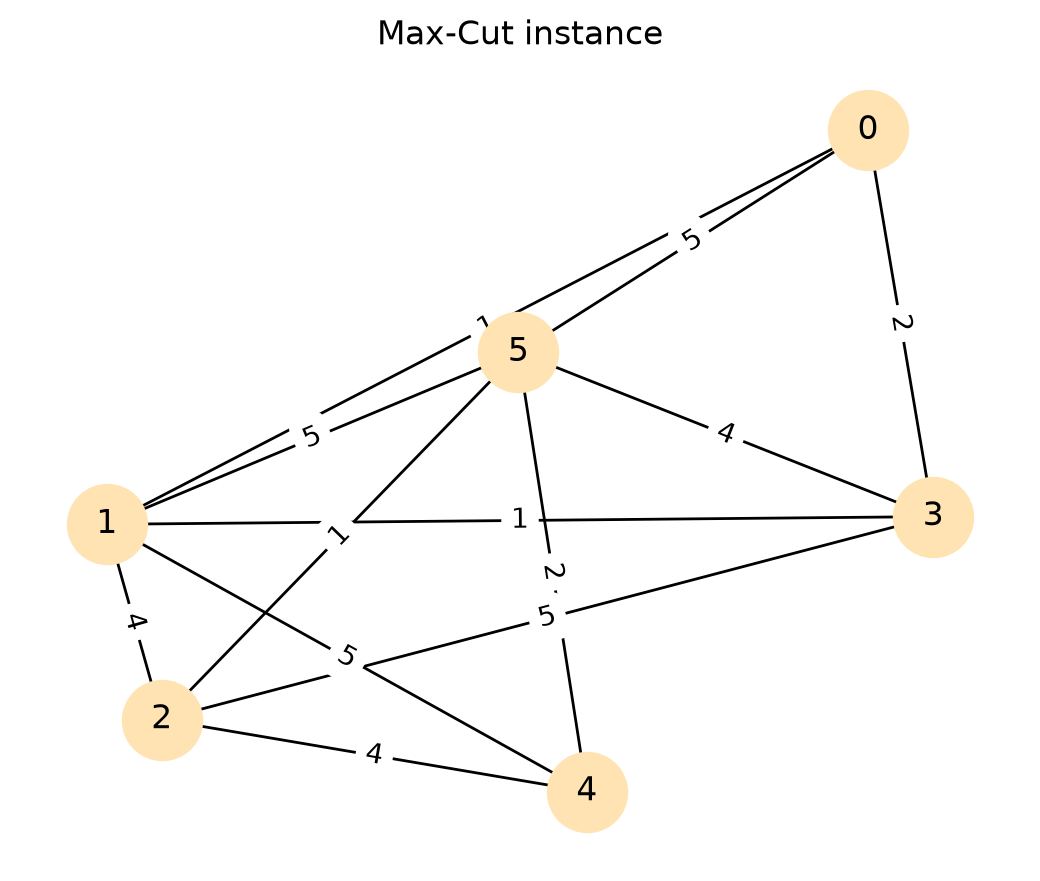

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))

from IPython.display import Image, display
from src.processors import load_processor
from src.problem import make_graph
from src.visualization import plot_coupling_map, plot_weighted_graph

procA = load_processor("processors/processor_A.json")
procB = load_processor("processors/processor_B.json")
plot_coupling_map(procA, "results/figures/processor_A_graph.png")
plot_coupling_map(procB, "results/figures/processor_B_graph.png")

N = 6
edges = make_graph(N, seed=42)
plot_weighted_graph(edges, N, "results/figures/problem_graph.png")

# save the instance so the run is reproducible
Path("data/raw").mkdir(parents=True, exist_ok=True)
with open("data/raw/instance_seed42.txt", "w") as f:
    f.write("# i j w\n")
    for i, j, w in edges:
        f.write(f"{i} {j} {w}\n")

for p in ["processor_A_graph", "processor_B_graph", "problem_graph"]:
    display(Image(f"results/figures/{p}.png"))